# Option A (384 px + weight decay): Healthy+Benign vs OPMD+OCA, with patient metadata

Adds the patient metadata (age, sex, smoking, alcohol, betel-quid chewing) to the image models, like Devindi et al. (IEEE Access 2024).
**Screening task:** **Healthy + Benign** ("not suspicious") vs **OPMD + OCA** ("suspicious, refer"), on the same Zenodo
**patient-level** split. Unlike the paper replication, Healthy images are now included, so the model knows what a healthy mouth looks like.
The test results are also broken down by original class (how many Healthy / Benign were cleared, how many OPMD / OCA were caught).

| Group | Method | What it does |
|---|---|---|
| Baselines | Image only | Image model alone (same recipe as the previous run) |
| | Metadata only | XGBoost on the metadata alone |
| Early fusion (feature level, trained end to end) | **E1 Concat** (paper style) | image features → 128, metadata → 32, joined → FC (GELU) → output |
| | **E2 Gated (FiLM)** | metadata produces per-feature scales/shifts that modulate the image features |
| Late fusion (decision level: image-only model + metadata-only model) | **L1 Simple average** | mean of the two probabilities |
| | **L2 Weighted average** | weight chosen on validation (by MCC) |
| | **L3 Stacking, logistic regression** | learns how to combine the two probabilities (fitted on validation) |
| | **L4 Stacking, XGBoost** | combines the image probability with the raw metadata (fitted on validation) |

Image models: **MobileNetV2, MobileNetV4-Conv-S, EfficientNet-B0** (top 3 of the previous run) and **MobileNetV3-Large** (the paper's model).
Same as the Option A run, with three changes to reduce overfitting and keep more lesion detail:
**384 px images** (was 224), **AdamW weight decay 0.05** (was Adam, none), and **30-60 epochs** with early stopping (was 200;
the models peaked by epoch 9-70). Best epoch by **validation MCC**. Results go to a separate folder for a 224-vs-384 comparison.

**Kaggle inputs:** `segmented-zenodo` (images) and `metadata-zenodo` (the image-wise and patient-wise CSV files) · GPU T4 · Internet ON.
Everything is saved to `/kaggle/working/metadata_fusion/` (plots, results, all models) and zipped as `models.zip`.

In [1]:
# ============================================================
# 1. CONFIG
# ============================================================
from pathlib import Path
SPLIT_ROOT = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")
META_ROOT  = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo")   # folder with the image-wise + patient-wise CSVs
OUT_DIR    = Path("/kaggle/working/metadata_fusion_optionA_384_wd")

CLASSES = ["Healthy+Benign", "OPMD+OCA"]                        # 0 = not suspicious, 1 = suspicious
FOLDERS = {"Healthy+Benign": ["Healthy", "Benign"], "OPMD+OCA": ["OPMD", "OCA"]}

BACKBONES = [
    dict(name="MobileNetV2",        timm_id="mobilenetv2_100.ra_in1k"),
    dict(name="MobileNetV4-Conv-S", timm_id="mobilenetv4_conv_small.e1200_r224_in1k"),
    dict(name="EfficientNet-B0",    timm_id="efficientnet_b0.ra_in1k"),
    dict(name="MobileNetV3-Large",  timm_id="mobilenetv3_large_100.ra_in1k"),     # the paper's encoder
]
NN_METHODS = ["Image only", "E1 Concat", "E2 Gated (FiLM)"]     # trained networks
ONLY_RUN = ["MobileNetV4-Conv-S", "EfficientNet-B0"]   # best two from the 224 px run; None = all four

# Metadata columns: None = detect automatically from the column names (printed below).
# If detection picks the wrong column, write the exact column name here.
META_COLS = {"age": None, "sex": None, "smoking": None, "alcohol": None, "betel": None}

IMG_SIZE, BATCH_SIZE, DROPOUT, LABEL_SMOOTHING = 384, 16, 0.5, 0.1   # 384 px (was 224), batch 16 for GPU memory
WEIGHT_DECAY = 0.05                                                 # AdamW weight decay (was 0 with Adam)
PHASE1_EPOCHS, PHASE1_LR, PHASE2_LR = 10, 1e-3, 1e-4
MIN_EPOCHS, MAX_EPOCHS, PATIENCE = 30, 60, 10       # models peaked by epoch 9-70 in the 224 px run
PLATEAU_FACTOR, PLATEAU_PATIENCE = 0.5, 5
USE_AMP, SEED, NUM_WORKERS = True, 42, 2

In [2]:
# ============================================================
# 2. IMPORTS
# ============================================================
import os, sys, gc, json, time, math, copy, random, shutil, subprocess, warnings, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image, ImageFile
from concurrent.futures import ThreadPoolExecutor
ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")
for mod, pip in (("timm", "timm"), ("xgboost", "xgboost")):
    try:
        __import__(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip])
import timm, xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, confusion_matrix, balanced_accuracy_score, classification_report)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = USE_AMP and DEVICE.type == "cuda"
print("Device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__, "| xgboost", xgb.__version__)
PLOT_DIR, MODEL_DIR = OUT_DIR / "plots", OUT_DIR / "models"
for d in (PLOT_DIR / "comparison", MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT_DIR / "results.csv"


def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def safe(s):
    return s.replace(" ", "_").replace("+", "plus").replace("(", "").replace(")", "")


def walk_files(root):
    return [Path(d) / f for d, _, fs in os.walk(root, followlinks=True) for f in fs]

Device: cuda | torch 2.11.0+cu130 | timm 1.0.30 | xgboost 3.4.1


## 3. Images (patient-level split) and metadata

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def patient_id(stem):
    p = stem.split("-")
    return f"{p[0]}-{p[1]}" if len(p) >= 2 else stem


rows = []
for split in ("train", "val", "test"):
    for label, (cls, folders) in enumerate(FOLDERS.items()):
        for f in folders:
            d = SPLIT_ROOT / split / f
            assert d.is_dir(), f"Missing {d} -- check SPLIT_ROOT"
            for p in sorted(d.iterdir()):
                if p.suffix.lower() in IMG_EXTS:
                    rows.append(dict(path=str(p), stem=p.stem, split=split, cls=cls, source=f, label=label,
                                     patient=patient_id(p.stem)))
df = pd.DataFrame(rows)
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not (set(df[df.split == a].patient) & set(df[df.split == b].patient)), f"Patient leakage {a}/{b}"
print(df.groupby(["split", "cls", "source"]).size().unstack([1, 2]))

# ---------------- metadata files ----------------
csvs = [p for p in walk_files(META_ROOT) if p.suffix.lower() in (".csv", ".xlsx", ".xls")]
print("\nMetadata files found:")
tables = {}
for p in csvs:
    t = pd.read_csv(p) if p.suffix.lower() == ".csv" else pd.read_excel(p)
    t.columns = [str(c).strip() for c in t.columns]
    tables[p.name] = t
    print(f"  {p.name}: {t.shape} columns = {list(t.columns)}")


def find_col(t, *keys, exclude=()):
    for c in t.columns:
        lc = c.lower().replace("_", " ")
        if all(k in lc for k in keys) and not any(e in lc for e in exclude):
            return c
    return None


img_tab = next((t for n, t in tables.items() if "image" in n.lower()), None)
pat_tab = next((t for n, t in tables.items() if "patient" in n.lower()), None)
assert pat_tab is not None, "Patient-wise metadata file not found -- check META_ROOT"

KEYS = {"age": [("age",)], "sex": [("gender",), ("sex",)], "smoking": [("smok",)],
        "alcohol": [("alcohol",)], "betel": [("betel",), ("chew",), ("quid",)]}
cols = {}
for k, opts in KEYS.items():
    cols[k] = META_COLS.get(k) or next((c for o in opts if (c := find_col(pat_tab, *o, exclude=("count", "image")))), None)
print("\nMetadata columns used:", cols)
missing = [k for k, c in cols.items() if c is None]
if missing:
    print("WARNING: not found:", missing, "-> set them in META_COLS (config cell) if they exist under another name")
cols = {k: c for k, c in cols.items() if c is not None}
assert cols, "No metadata columns detected -- set META_COLS by hand"

# join: image file name -> patient id (first two '-' parts, same rule as the split) -> patient-wise row
import re
pc = find_col(pat_tab, "patient")
VARIANTS = {   # ways to turn an id into a comparable key; the one matching the most images is used
    "as is":         lambda v: str(v).strip().lower(),
    "first 2 parts": lambda v: "-".join(str(v).strip().lower().replace("_", "-").split("-")[:2]),
    "first part":    lambda v: str(v).strip().lower().replace("_", "-").split("-")[0],
    "digits":        lambda v: "-".join(str(int(x)) for x in re.findall(r"\d+", str(v))[:2]),
}
pat_ids = pat_tab[pc]
best = max(VARIANTS, key=lambda k: df["patient"].map(VARIANTS[k]).isin(set(pat_ids.map(VARIANTS[k]))).mean())
key = VARIANTS[best]
pat = pat_tab.copy(); pat["_pid"] = pat_ids.map(key); df["_pid"] = df["patient"].map(key)
df = df.merge(pat[["_pid"] + list(cols.values())].drop_duplicates("_pid"), on="_pid", how="left")
print(f"Matched images to patients using id rule '{best}'. Examples -- image patient ids: {df['patient'].head(3).tolist()}"
      f" | metadata ids: {pat_ids.head(3).tolist()}")
cover = 1 - df[list(cols.values())].isna().all(1).mean()
print(f"Images with metadata: {cover:.1%}")
display(df[["stem", "split", "cls"] + list(cols.values())].head())

cls    Healthy+Benign         OPMD+OCA     
source         Benign Healthy      OCA OPMD
split                                      
test              128     125       37  260
train             492     481       76  884
val               128     123       16  250

Metadata files found:
  Imagewise_Data.csv: (3000, 4) columns = ['Image Name', 'Category', 'Clinical Diagnosis', 'Lesion Annotation Count']
  Patientwise_Data.csv: (714, 7) columns = ['Patient ID', 'Age', 'Gender', 'Smoking', 'Chewing_Betel_Quid', 'Alcohol', 'Image Count']

Metadata columns used: {'age': 'Age', 'sex': 'Gender', 'smoking': 'Smoking', 'alcohol': 'Alcohol', 'betel': 'Chewing_Betel_Quid'}
Matched images to patients using id rule 'as is'. Examples -- image patient ids: ['C-10', 'C-10', 'C-10'] | metadata ids: ['R-01', 'R-02', 'R-03']
Images with metadata: 100.0%


,stem,split,cls,Age,Gender,Smoking,Alcohol,Chewing_Betel_Quid
0,C-10-12-5,train,Healthy+Benign,26,F,No,No,No
1,C-10-2-7,train,Healthy+Benign,26,F,No,No,No
2,C-10-3-6,train,Healthy+Benign,26,F,No,No,No
3,C-10-4-3,train,Healthy+Benign,26,F,No,No,No
4,C-10-5-4,train,Healthy+Benign,26,F,No,No,No


Metadata vector size: 9  -> ['m_age', 'm_sex=f', 'm_sex=m', 'm_smoking=no', 'm_smoking=yes', 'm_alcohol=no', 'm_alcohol=yes', 'm_betel=no', 'm_betel=yes']


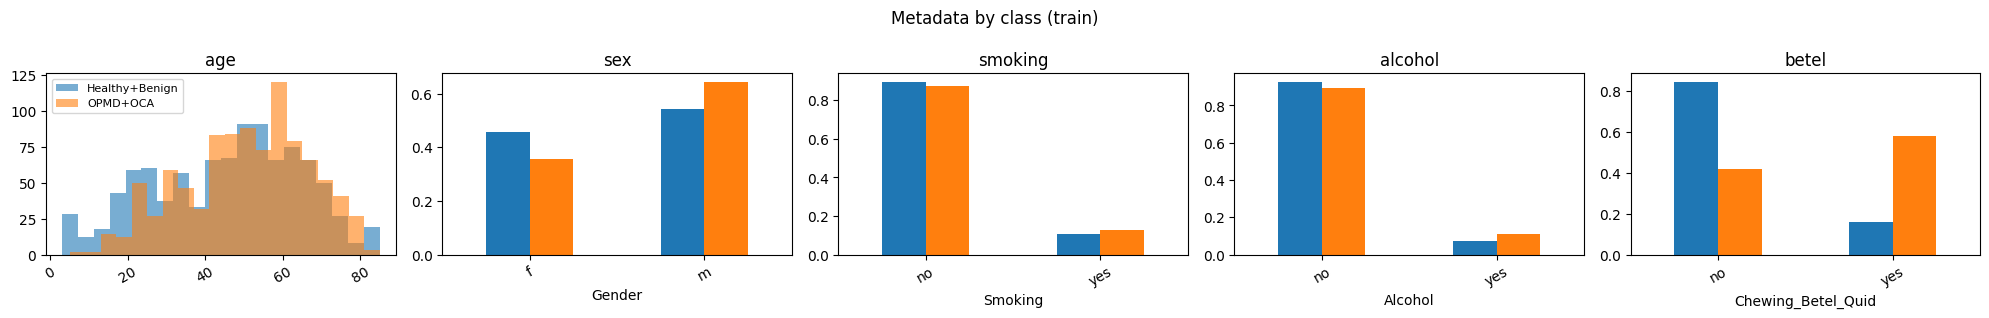

Loaded 3000 images in 306s


In [4]:
# ---------------- encode metadata (fitted on TRAIN only) ----------------
train_mask = (df.split == "train").values
ENC = {"numeric": {}, "categorical": {}}
feat_cols = []
for k, c in cols.items():
    s = df[c]
    num = pd.to_numeric(s, errors="coerce")
    if k == "age" or (num.notna().mean() > 0.9 and s.nunique() > 10):
        med = float(num[train_mask].median()); lo, hi = float(num[train_mask].min()), float(num[train_mask].max())
        df[f"m_{k}"] = ((num.fillna(med) - lo) / max(hi - lo, 1e-6)).clip(0, 1)
        ENC["numeric"][c] = dict(median=med, min=lo, max=hi); feat_cols.append(f"m_{k}")
    else:
        v = s.astype(str).str.strip().str.lower().replace({"nan": "unknown", "": "unknown"})
        cats = sorted(v[train_mask].unique().tolist())
        ENC["categorical"][c] = cats
        for cat in cats:
            df[f"m_{k}={cat}"] = (v == cat).astype(float); feat_cols.append(f"m_{k}={cat}")
META_DIM = len(feat_cols)
print(f"Metadata vector size: {META_DIM}  ->", feat_cols)

M = {s: df.loc[df.split == s, feat_cols].values.astype(np.float32) for s in ("train", "val", "test")}
Y = {s: df.loc[df.split == s, "label"].values.astype(np.int64) for s in ("train", "val", "test")}
PATHS = {s: df.loc[df.split == s, "path"].tolist() for s in ("train", "val", "test")}
SOURCE = {s: df.loc[df.split == s, "source"].values for s in ("train", "val", "test")}

fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.2), squeeze=False)
tr = df[df.split == "train"]
for a, (k, c) in zip(axes[0], cols.items()):
    if c in ENC["numeric"]:
        for i, cl in enumerate(CLASSES):
            a.hist(pd.to_numeric(tr[tr.label == i][c], errors="coerce").dropna(), bins=20, alpha=.6, label=cl)
    else:
        pd.crosstab(tr[c].astype(str).str.lower(), tr.cls, normalize="columns").plot.bar(ax=a, legend=False)
    a.set_title(k); a.tick_params(axis="x", rotation=30)
axes[0][0].legend(fontsize=8); fig.suptitle("Metadata by class (train)"); plt.tight_layout()
fig.savefig(PLOT_DIR / "comparison" / "00_metadata_by_class.png", dpi=120); plt.show()

# ---------------- images into memory ----------------
PRE = max(256, IMG_SIZE + 32)          # stored size must be >= IMG_SIZE, otherwise no extra detail
def load_one(p):
    return np.asarray(Image.open(p).convert("RGB").resize((PRE, PRE), Image.BICUBIC))
t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    IMGS = {s: np.stack(list(ex.map(load_one, PATHS[s]))) for s in ("train", "val", "test")}
print(f"Loaded {sum(len(v) for v in IMGS.values())} images in {time.time() - t0:.0f}s")
cnt = np.bincount(Y["train"], minlength=2)
CLASS_WEIGHTS = torch.tensor(len(Y["train"]) / (2 * cnt), dtype=torch.float32)


class DS(Dataset):
    def __init__(self, s, tf):
        self.s, self.tf = s, tf
    def __len__(self):
        return len(Y[self.s])
    def __getitem__(self, i):
        return self.tf(Image.fromarray(IMGS[self.s][i])), torch.from_numpy(M[self.s][i]), Y[self.s][i]


def make_tf(mean, std):
    tr = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomHorizontalFlip(), T.RandomAffine(degrees=15, scale=(0.9, 1.1)),
                    T.ColorJitter(contrast=0.1), T.ToTensor(), T.Normalize(mean, std)])
    ev = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(mean, std)])
    return tr, ev

## 4. Models: image only, E1 concat, E2 gated (FiLM)

In [5]:
class FusionNet(nn.Module):
    def __init__(self, timm_id, method, meta_dim):
        super().__init__()
        self.method = method
        self.backbone = timm.create_model(timm_id, pretrained=True, num_classes=0)
        self.backbone.eval()
        with torch.no_grad():                              # real output size (MobileNetV3/V4 add a conv head after pooling)
            f = self.backbone(torch.zeros(1, 3, 96, 96)).shape[1]
        if method == "Image only":
            self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(f, 2))
        elif method == "E1 Concat":                       # paper style: 128 image + 32 metadata features
            self.img_proj = nn.Sequential(nn.Linear(f, 128), nn.GELU())
            self.meta_proj = nn.Sequential(nn.Linear(meta_dim, 32), nn.GELU())
            self.head = nn.Sequential(nn.Linear(160, 64), nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(64, 2))
        elif method == "E2 Gated (FiLM)":                 # metadata -> per-feature scale and shift of the image features
            self.film = nn.Sequential(nn.Linear(meta_dim, 64), nn.GELU(), nn.Linear(64, 2 * f))
            nn.init.zeros_(self.film[-1].weight); nn.init.zeros_(self.film[-1].bias)   # starts as "no modulation"
            self.head = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(f, 2))
        else:
            raise ValueError(method)

    def forward(self, x, m):
        h = self.backbone(x)
        if self.method == "E1 Concat":
            return self.head(torch.cat([self.img_proj(h), self.meta_proj(m)], 1))
        if self.method == "E2 Gated (FiLM)":
            g, b = self.film(m).chunk(2, 1)
            h = h * (1 + torch.tanh(g)) + b
        return self.head(h)


class NonFinite(RuntimeError):
    pass


@torch.no_grad()
def predict(model, loader):
    model.eval(); P = []
    for x, m, _ in loader:
        P.append(model(x.to(DEVICE), m.to(DEVICE)).float().softmax(1)[:, 1].cpu())
    P = torch.cat(P).numpy()
    if not np.isfinite(P).all():
        raise NonFinite("NaN outputs")
    return P


def metrics(y, p1, thr=0.5):
    pred = (p1 >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {k: float(v) for k, v in dict(
        accuracy=accuracy_score(y, pred), macro_precision=pr.mean(), macro_recall=rc.mean(),
        macro_f1=f1_score(y, pred, average="macro"), mcc=matthews_corrcoef(y, pred),
        balanced_accuracy=balanced_accuracy_score(y, pred), roc_auc=roc_auc_score(y, p1),
        sensitivity_OPMD_OCA=rc[1], specificity_Benign=rc[0]).items()}, confusion_matrix(y, pred, labels=[0, 1])


def train_nn(spec, method, use_amp):
    seed_everything(SEED)
    model = FusionNet(spec["timm_id"], method, META_DIM).to(DEVICE)
    cfg = timm.data.resolve_model_data_config(model.backbone); mean, std = cfg["mean"], cfg["std"]
    tf_tr, tf_ev = make_tf(mean, std)
    g = torch.Generator().manual_seed(SEED)
    dl_tr = DataLoader(DS("train", tf_tr), BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=g, pin_memory=True)
    dl_va = DataLoader(DS("val", tf_ev), 64, num_workers=NUM_WORKERS)
    body = list(model.backbone.parameters()); bid = {id(p) for p in body}
    rest = [p for p in model.parameters() if id(p) not in bid]
    crit = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), label_smoothing=LABEL_SMOOTHING)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    def new_phase(phase):
        for p in body:
            p.requires_grad_(phase == 2)
        opt = torch.optim.AdamW(rest if phase == 1 else rest + body, lr=PHASE1_LR if phase == 1 else PHASE2_LR,
                                weight_decay=WEIGHT_DECAY)
        return opt, torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "min", PLATEAU_FACTOR, PLATEAU_PATIENCE, min_lr=1e-7)

    opt, sch = new_phase(1)
    hist, best, best_state, bad, t0 = [], -2.0, None, 0, time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        if ep == PHASE1_EPOCHS + 1:
            opt, sch = new_phase(2)
        phase = 1 if ep <= PHASE1_EPOCHS else 2
        model.train()
        if phase == 1:
            for mod in model.backbone.modules():
                if isinstance(mod, nn.modules.batchnorm._BatchNorm):
                    mod.eval()
        tl = tc = tn = 0
        for x, m, y in dl_tr:
            x, m, y = x.to(DEVICE, non_blocking=True), m.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                out = model(x, m); loss = crit(out.float(), y)
            if not torch.isfinite(loss):
                raise NonFinite(f"loss {loss.item()} at epoch {ep}")
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv = predict(model, dl_va)
        vl = F.cross_entropy(torch.tensor(np.log(np.stack([1 - pv, pv], 1) + 1e-8)), torch.tensor(Y["val"])).item()
        mv, _ = metrics(Y["val"], pv); sch.step(vl)
        hist.append(dict(epoch=ep, phase=phase, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=mv["accuracy"],
                         val_mcc=mv["mcc"], val_macro_f1=mv["macro_f1"], lr=opt.param_groups[0]["lr"]))
        if mv["mcc"] > best:
            best, bad = mv["mcc"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        print(f"  ep {ep:3d} [p{phase}] train loss {tl / tn:.3f} acc {tc / tn:.3f} | val loss {vl:.3f} acc {mv['accuracy']:.3f} "
              f"MCC {mv['mcc']:.3f} F1 {mv['macro_f1']:.3f}{'  *' if bad == 0 else ''}")
        if ep >= MIN_EPOCHS and bad >= PATIENCE:
            print(f"  early stop at epoch {ep} (best val MCC {best:.3f})"); break
    model.load_state_dict(best_state)
    probs = {s: predict(model, DataLoader(DS(s, tf_ev), 64, num_workers=NUM_WORKERS)) for s in ("val", "test")}
    return model, pd.DataFrame(hist), probs, dict(mean=list(mean), std=list(std)), (time.time() - t0) / 60

## 5. Plot helpers

In [6]:
def plot_curves(h, title, path):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("Loss")
    ax[1].plot(h.epoch, h.train_acc, label="train (augmented)"); ax[1].plot(h.epoch, h.val_acc, label="val"); ax[1].set_title("Accuracy")
    ax[2].plot(h.epoch, h.val_mcc, label="val MCC"); ax[2].plot(h.epoch, h.val_macro_f1, label="val macro-F1")
    b = h.val_mcc.idxmax(); ax[2].axvline(h.epoch[b], ls="--", c="gray", lw=1, label=f"best epoch {h.epoch[b]}"); ax[2].set_title("Validation")
    for a in ax:
        a.axvline(PHASE1_EPOCHS + .5, c="k", ls=":", lw=.8); a.grid(alpha=.3); a.legend(fontsize=8); a.set_xlabel("epoch")
    fig.suptitle(title); plt.tight_layout(); fig.savefig(path, dpi=110); plt.show()


def plot_cm(cm, title, path):
    fig, ax = plt.subplots(figsize=(4.2, 3.8)); Mn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({Mn[i, j]:.2f})", ha="center", va="center", color="white" if Mn[i, j] > .5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(CLASSES); ax.set_yticks([0, 1]); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=9); plt.tight_layout(); fig.savefig(path, dpi=110); plt.show()

## 6. Metadata-only model (XGBoost)

-> -                  Metadata only          val MCC 0.454 | TEST acc 0.711 MCC 0.433 F1 0.711 AUC 0.800 | cleared Healthy 75% Benign 81% | caught OPMD 65% OCA 65%


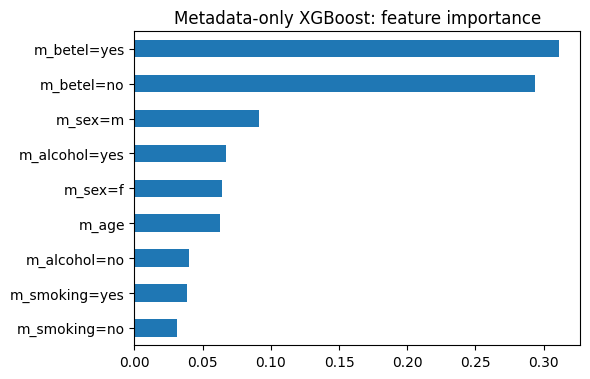

In [7]:
xgb_params = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  scale_pos_weight=float(cnt[0] / cnt[1]), eval_metric="logloss", random_state=SEED)
meta_model = xgb.XGBClassifier(**xgb_params).fit(M["train"], Y["train"])
META_P = {s: meta_model.predict_proba(M[s])[:, 1] for s in ("val", "test")}
(MODEL_DIR / "Metadata_only").mkdir(parents=True, exist_ok=True)
meta_model.save_model(str(MODEL_DIR / "Metadata_only" / "xgboost.json"))
json.dump(dict(features=feat_cols, columns=cols, encoding=ENC), open(MODEL_DIR / "metadata_encoding.json", "w"), indent=2)

RESULTS, PROBS, CMS = [], {}, {}
def record(backbone, method, group, probs, extra=None):
    row = dict(backbone=backbone, method=method, group=group, **(extra or {}))
    for s in ("val", "test"):
        m, cm = metrics(Y[s], probs[s]); row.update({f"{s}_{k}": v for k, v in m.items()}); CMS[(backbone, method, s)] = cm
    src = SOURCE["test"]; pred_t = (probs["test"] >= 0.5).astype(int)
    for f in ("Healthy", "Benign", "OPMD", "OCA"):                     # share of each original class predicted correctly
        sel = src == f
        if sel.any():
            row[f"test_{f}_correct"] = float((pred_t[sel] == (0 if f in ("Healthy", "Benign") else 1)).mean())
    PROBS[(backbone, method)] = probs; RESULTS.append(row)
    print(f"-> {backbone:18s} {method:22s} val MCC {row['val_mcc']:.3f} | TEST acc {row['test_accuracy']:.3f} "
          f"MCC {row['test_mcc']:.3f} F1 {row['test_macro_f1']:.3f} AUC {row['test_roc_auc']:.3f} | cleared Healthy "
          f"{row.get('test_Healthy_correct', 0):.0%} Benign {row.get('test_Benign_correct', 0):.0%} | caught OPMD "
          f"{row.get('test_OPMD_correct', 0):.0%} OCA {row.get('test_OCA_correct', 0):.0%}")
    return row

record("-", "Metadata only", "Baseline", META_P)
imp = pd.Series(meta_model.feature_importances_, index=feat_cols).sort_values()
fig, ax = plt.subplots(figsize=(6, 0.3 * len(imp) + 1.2)); imp.plot.barh(ax=ax); ax.set_title("Metadata-only XGBoost: feature importance")
plt.tight_layout(); fig.savefig(PLOT_DIR / "comparison" / "01_metadata_importance.png", dpi=120); plt.show()

## 7. Train image-only, E1 and E2 for every backbone, then late fusion L1-L4


MobileNetV4-Conv-S | Image only


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1 [p1] train loss 0.681 acc 0.580 | val loss 0.651 acc 0.596 MCC 0.291 F1 0.547  *
  ep   2 [p1] train loss 0.653 acc 0.619 | val loss 0.625 acc 0.662 MCC 0.384 F1 0.644  *
  ep   3 [p1] train loss 0.643 acc 0.646 | val loss 0.616 acc 0.663 MCC 0.374 F1 0.650
  ep   4 [p1] train loss 0.627 acc 0.667 | val loss 0.585 acc 0.698 MCC 0.402 F1 0.692  *
  ep   5 [p1] train loss 0.633 acc 0.657 | val loss 0.580 acc 0.714 MCC 0.433 F1 0.713  *
  ep   6 [p1] train loss 0.628 acc 0.660 | val loss 0.572 acc 0.708 MCC 0.415 F1 0.708
  ep   7 [p1] train loss 0.625 acc 0.667 | val loss 0.574 acc 0.712 MCC 0.428 F1 0.712
  ep   8 [p1] train loss 0.632 acc 0.665 | val loss 0.567 acc 0.721 MCC 0.448 F1 0.721  *
  ep   9 [p1] train loss 0.627 acc 0.658 | val loss 0.565 acc 0.727 MCC 0.458 F1 0.727  *
  ep  10 [p1] train loss 0.612 acc 0.678 | val loss 0.562 acc 0.723 MCC 0.450 F1 0.723
  ep  11 [p2] train loss 0.822 acc 0.577 | val loss 0.654 acc 0.619 MCC 0.256 F1 0.613
  ep  12 [p2] train loss 

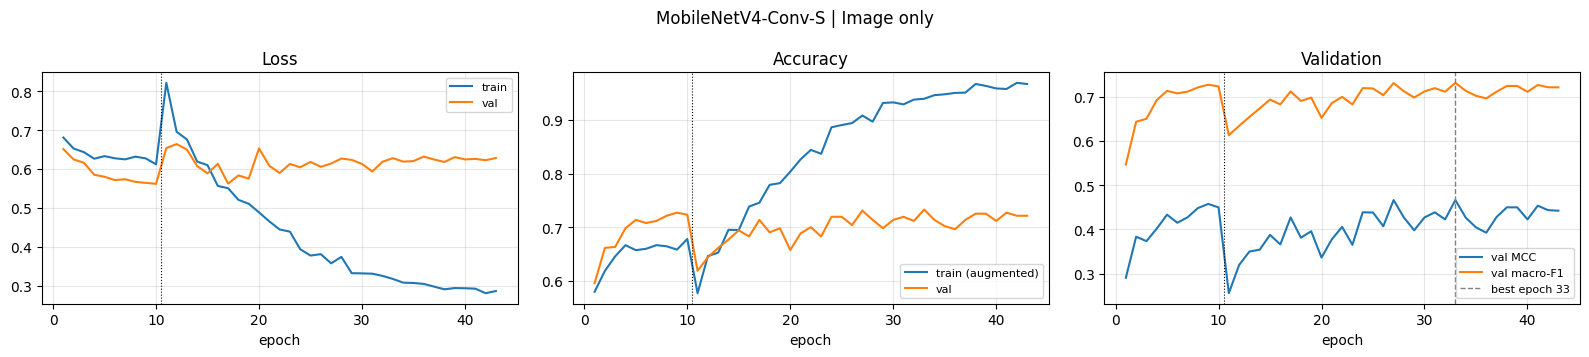

-> MobileNetV4-Conv-S Image only             val MCC 0.467 | TEST acc 0.711 MCC 0.416 F1 0.708 AUC 0.758 | cleared Healthy 67% Benign 64% | caught OPMD 75% OCA 78%


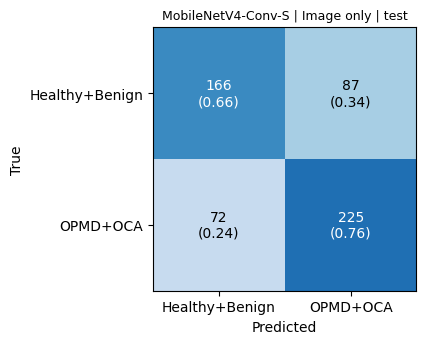

-> MobileNetV4-Conv-S L1 Simple average      val MCC 0.539 | TEST acc 0.745 MCC 0.487 F1 0.744 AUC 0.830 | cleared Healthy 76% Benign 68% | caught OPMD 78% OCA 68%
-> MobileNetV4-Conv-S L2 Weighted average    val MCC 0.547 | TEST acc 0.756 MCC 0.510 F1 0.755 AUC 0.833 | cleared Healthy 80% Benign 68% | caught OPMD 78% OCA 68%
-> MobileNetV4-Conv-S L3 Stacking (LogReg)   val MCC 0.551 | TEST acc 0.735 MCC 0.481 F1 0.735 AUC 0.836 | cleared Healthy 86% Benign 77% | caught OPMD 69% OCA 51%
-> MobileNetV4-Conv-S L4 Stacking (XGBoost)  val MCC 0.574 | TEST acc 0.751 MCC 0.517 F1 0.751 AUC 0.816 | cleared Healthy 90% Benign 77% | caught OPMD 65% OCA 86%

MobileNetV4-Conv-S | E1 Concat
  ep   1 [p1] train loss 0.650 acc 0.654 | val loss 0.565 acc 0.760 MCC 0.530 F1 0.759  *
  ep   2 [p1] train loss 0.593 acc 0.715 | val loss 0.562 acc 0.758 MCC 0.526 F1 0.757
  ep   3 [p1] train loss 0.573 acc 0.734 | val loss 0.510 acc 0.754 MCC 0.513 F1 0.754
  ep   4 [p1] train loss 0.555 acc 0.747 | val l

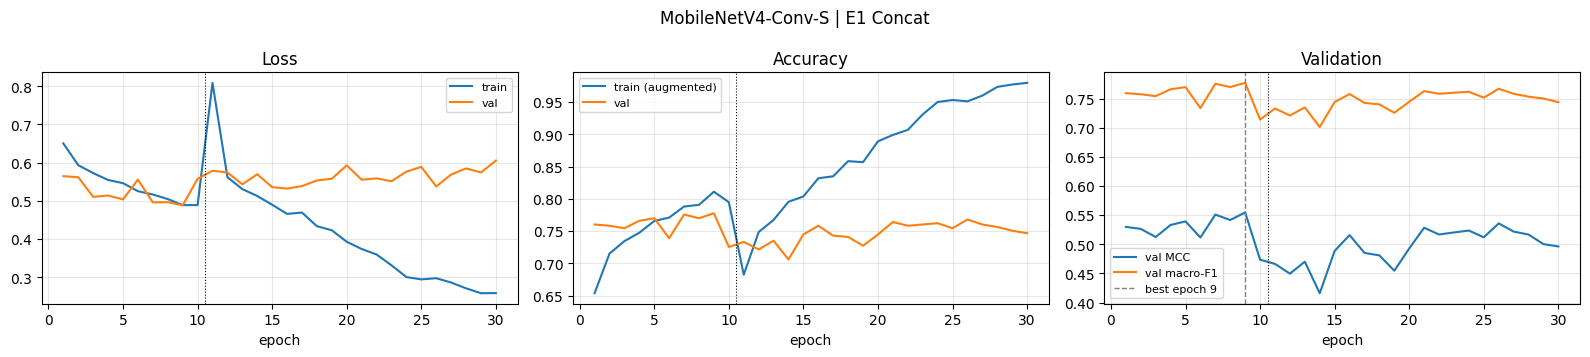

-> MobileNetV4-Conv-S E1 Concat              val MCC 0.555 | TEST acc 0.755 MCC 0.508 F1 0.754 AUC 0.823 | cleared Healthy 77% Benign 75% | caught OPMD 73% OCA 86%


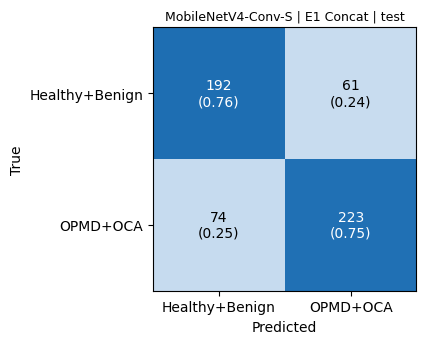


MobileNetV4-Conv-S | E2 Gated (FiLM)
  ep   1 [p1] train loss 0.622 acc 0.686 | val loss 0.535 acc 0.764 MCC 0.531 F1 0.764  *
  ep   2 [p1] train loss 0.588 acc 0.724 | val loss 0.569 acc 0.743 MCC 0.506 F1 0.740
  ep   3 [p1] train loss 0.574 acc 0.728 | val loss 0.511 acc 0.762 MCC 0.527 F1 0.762
  ep   4 [p1] train loss 0.567 acc 0.743 | val loss 0.523 acc 0.779 MCC 0.559 F1 0.779  *
  ep   5 [p1] train loss 0.560 acc 0.745 | val loss 0.516 acc 0.750 MCC 0.506 F1 0.750
  ep   6 [p1] train loss 0.553 acc 0.748 | val loss 0.531 acc 0.741 MCC 0.493 F1 0.740
  ep   7 [p1] train loss 0.548 acc 0.753 | val loss 0.511 acc 0.764 MCC 0.527 F1 0.764
  ep   8 [p1] train loss 0.546 acc 0.752 | val loss 0.525 acc 0.750 MCC 0.508 F1 0.750
  ep   9 [p1] train loss 0.550 acc 0.757 | val loss 0.514 acc 0.766 MCC 0.531 F1 0.766
  ep  10 [p1] train loss 0.541 acc 0.755 | val loss 0.508 acc 0.779 MCC 0.560 F1 0.778  *
  ep  11 [p2] train loss 0.626 acc 0.717 | val loss 0.532 acc 0.743 MCC 0.485 F1 0.

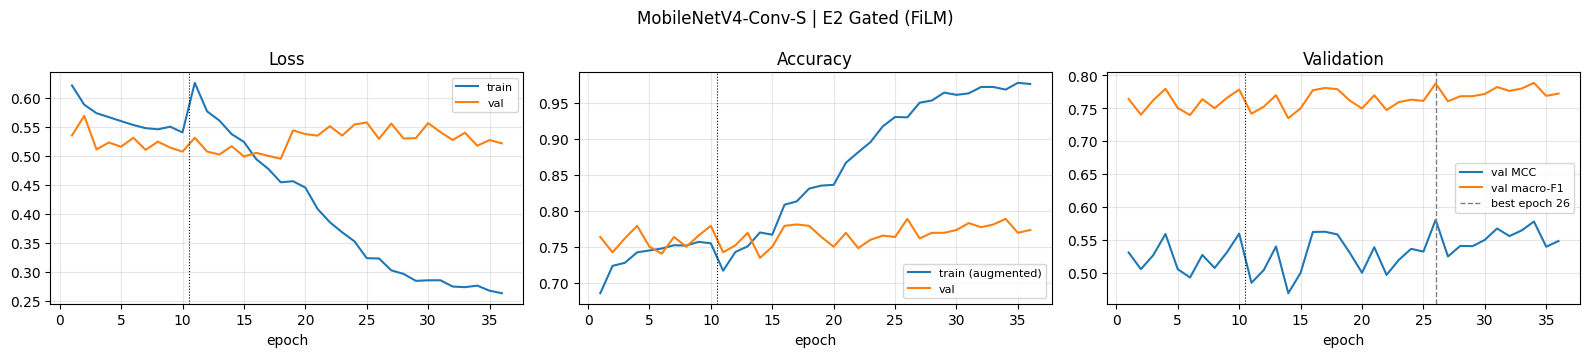

-> MobileNetV4-Conv-S E2 Gated (FiLM)        val MCC 0.581 | TEST acc 0.760 MCC 0.526 F1 0.760 AUC 0.838 | cleared Healthy 81% Benign 80% | caught OPMD 70% OCA 86%


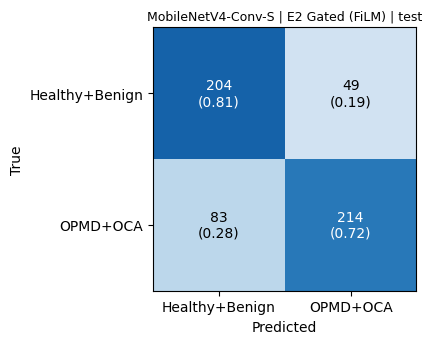


EfficientNet-B0 | Image only


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1 [p1] train loss 0.669 acc 0.610 | val loss 0.684 acc 0.565 MCC 0.239 F1 0.495  *
  ep   2 [p1] train loss 0.645 acc 0.641 | val loss 0.655 acc 0.621 MCC 0.341 F1 0.581  *
  ep   3 [p1] train loss 0.627 acc 0.676 | val loss 0.618 acc 0.673 MCC 0.415 F1 0.655  *
  ep   4 [p1] train loss 0.615 acc 0.684 | val loss 0.556 acc 0.731 MCC 0.464 F1 0.731  *
  ep   5 [p1] train loss 0.618 acc 0.672 | val loss 0.570 acc 0.704 MCC 0.415 F1 0.703
  ep   6 [p1] train loss 0.604 acc 0.713 | val loss 0.634 acc 0.654 MCC 0.379 F1 0.631
  ep   7 [p1] train loss 0.610 acc 0.694 | val loss 0.588 acc 0.710 MCC 0.454 F1 0.703
  ep   8 [p1] train loss 0.602 acc 0.700 | val loss 0.576 acc 0.706 MCC 0.434 F1 0.702
  ep   9 [p1] train loss 0.592 acc 0.703 | val loss 0.559 acc 0.702 MCC 0.406 F1 0.702
  ep  10 [p1] train loss 0.585 acc 0.716 | val loss 0.552 acc 0.702 MCC 0.404 F1 0.702
  ep  11 [p2] train loss 0.666 acc 0.636 | val loss 0.567 acc 0.723 MCC 0.446 F1 0.723
  ep  12 [p2] train loss 0.542 

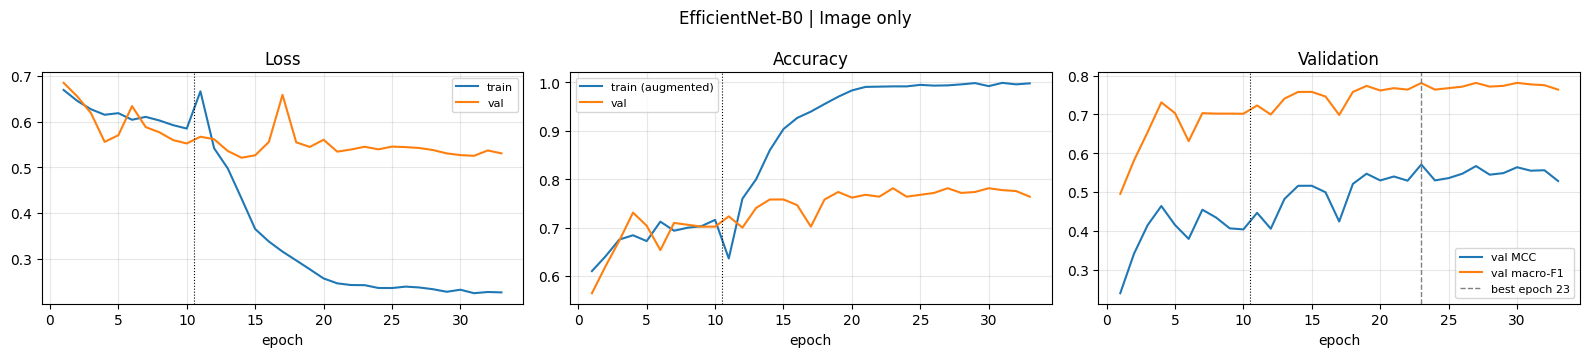

-> EfficientNet-B0    Image only             val MCC 0.571 | TEST acc 0.733 MCC 0.489 F1 0.732 AUC 0.813 | cleared Healthy 90% Benign 80% | caught OPMD 63% OCA 62%


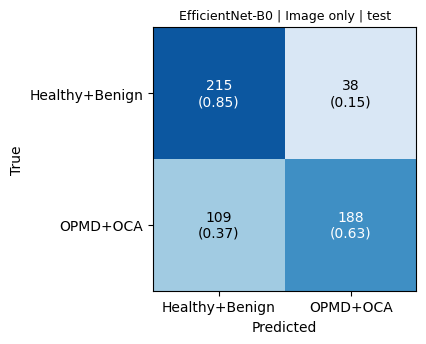

-> EfficientNet-B0    L1 Simple average      val MCC 0.582 | TEST acc 0.760 MCC 0.534 F1 0.760 AUC 0.866 | cleared Healthy 90% Benign 79% | caught OPMD 71% OCA 57%
-> EfficientNet-B0    L2 Weighted average    val MCC 0.609 | TEST acc 0.758 MCC 0.526 F1 0.758 AUC 0.865 | cleared Healthy 87% Benign 77% | caught OPMD 72% OCA 57%
-> EfficientNet-B0    L3 Stacking (LogReg)   val MCC 0.578 | TEST acc 0.758 MCC 0.528 F1 0.758 AUC 0.865 | cleared Healthy 89% Benign 78% | caught OPMD 71% OCA 57%
-> EfficientNet-B0    L4 Stacking (XGBoost)  val MCC 0.613 | TEST acc 0.785 MCC 0.585 F1 0.785 AUC 0.854 | cleared Healthy 91% Benign 83% | caught OPMD 68% OCA 95%

EfficientNet-B0 | E1 Concat
  ep   1 [p1] train loss 0.645 acc 0.635 | val loss 0.620 acc 0.665 MCC 0.414 F1 0.641  *
  ep   2 [p1] train loss 0.586 acc 0.716 | val loss 0.529 acc 0.760 MCC 0.526 F1 0.760  *
  ep   3 [p1] train loss 0.561 acc 0.742 | val loss 0.522 acc 0.741 MCC 0.495 F1 0.739
  ep   4 [p1] train loss 0.543 acc 0.754 | val l

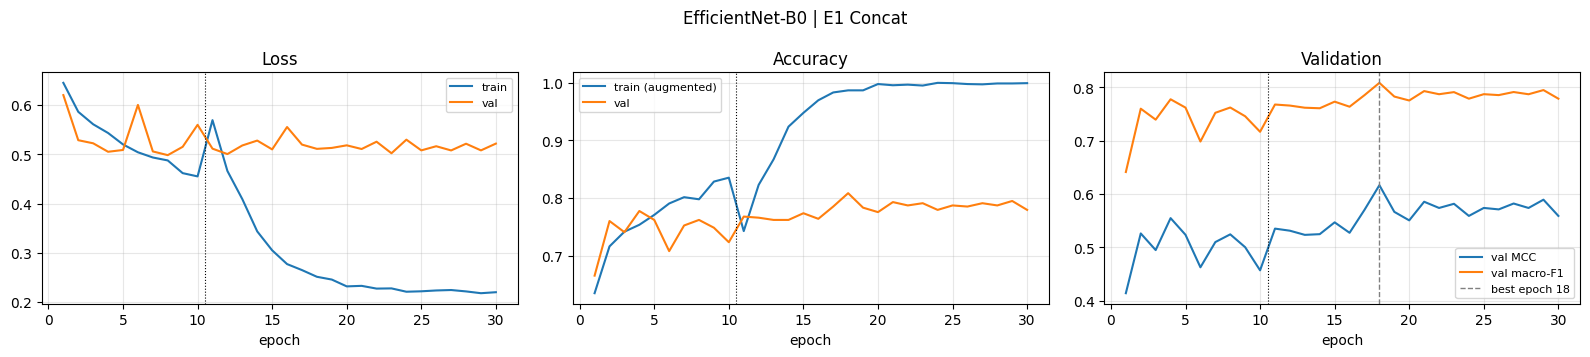

-> EfficientNet-B0    E1 Concat              val MCC 0.617 | TEST acc 0.762 MCC 0.534 F1 0.762 AUC 0.854 | cleared Healthy 91% Benign 75% | caught OPMD 69% OCA 81%


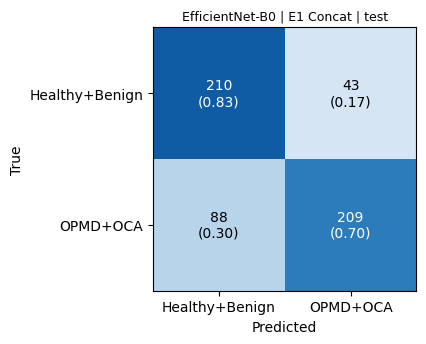


EfficientNet-B0 | E2 Gated (FiLM)
  ep   1 [p1] train loss 0.616 acc 0.682 | val loss 0.590 acc 0.716 MCC 0.464 F1 0.710  *
  ep   2 [p1] train loss 0.593 acc 0.723 | val loss 0.552 acc 0.735 MCC 0.488 F1 0.733  *
  ep   3 [p1] train loss 0.569 acc 0.742 | val loss 0.514 acc 0.762 MCC 0.530 F1 0.762  *
  ep   4 [p1] train loss 0.560 acc 0.755 | val loss 0.504 acc 0.779 MCC 0.558 F1 0.779  *
  ep   5 [p1] train loss 0.555 acc 0.743 | val loss 0.512 acc 0.743 MCC 0.490 F1 0.742
  ep   6 [p1] train loss 0.535 acc 0.764 | val loss 0.563 acc 0.716 MCC 0.466 F1 0.709
  ep   7 [p1] train loss 0.540 acc 0.765 | val loss 0.506 acc 0.749 MCC 0.497 F1 0.748
  ep   8 [p1] train loss 0.534 acc 0.767 | val loss 0.518 acc 0.756 MCC 0.525 F1 0.755
  ep   9 [p1] train loss 0.527 acc 0.772 | val loss 0.501 acc 0.779 MCC 0.560 F1 0.779  *
  ep  10 [p1] train loss 0.521 acc 0.779 | val loss 0.507 acc 0.770 MCC 0.540 F1 0.769
  ep  11 [p2] train loss 0.575 acc 0.735 | val loss 0.508 acc 0.762 MCC 0.525 F1

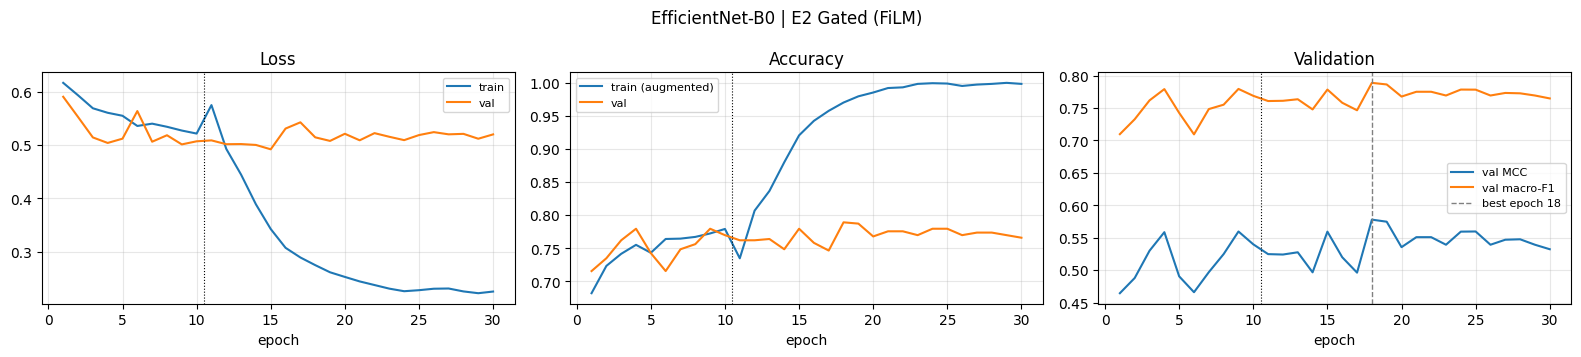

-> EfficientNet-B0    E2 Gated (FiLM)        val MCC 0.578 | TEST acc 0.775 MCC 0.560 F1 0.775 AUC 0.851 | cleared Healthy 88% Benign 81% | caught OPMD 70% OCA 81%


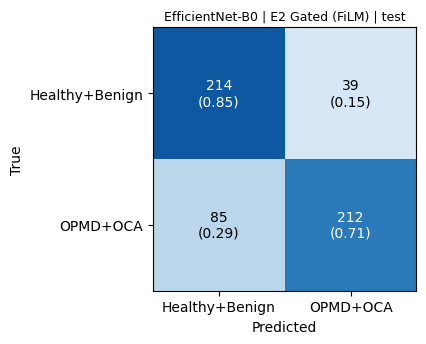

In [8]:
def late_fusion(bb, img_p):
    """L1-L4 from the image-only model's probabilities and the metadata (fitted on VALIDATION; val scores are cross-validated)."""
    yv = Y["val"]
    # L1 simple average
    record(bb, "L1 Simple average", "Late fusion", {s: (img_p[s] + META_P[s]) / 2 for s in ("val", "test")})
    # L2 weighted average, weight chosen on validation by MCC
    ws = np.linspace(0, 1, 21)
    w = ws[int(np.argmax([matthews_corrcoef(yv, ((w_ * img_p["val"] + (1 - w_) * META_P["val"]) >= .5).astype(int)) for w_ in ws]))]
    record(bb, "L2 Weighted average", "Late fusion", {s: w * img_p[s] + (1 - w) * META_P[s] for s in ("val", "test")},
           dict(image_weight=float(w)))
    # L3 stacking: logistic regression on the two logits
    lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    Z = {s: np.stack([lg(img_p[s]), lg(META_P[s])], 1) for s in ("val", "test")}
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    lr = LogisticRegression(class_weight="balanced", max_iter=1000)
    p_val = cross_val_predict(lr, Z["val"], yv, cv=cv, method="predict_proba")[:, 1]
    lr.fit(Z["val"], yv)
    record(bb, "L3 Stacking (LogReg)", "Late fusion", {"val": p_val, "test": lr.predict_proba(Z["test"])[:, 1]})
    # L4 stacking: XGBoost on [image probability + metadata]
    Xs = {s: np.column_stack([img_p[s], M[s]]) for s in ("val", "test")}
    xs = xgb.XGBClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, eval_metric="logloss",
                           scale_pos_weight=float((yv == 0).sum() / (yv == 1).sum()), random_state=SEED)
    p_val4 = cross_val_predict(xs, Xs["val"], yv, cv=cv, method="predict_proba")[:, 1]
    xs.fit(Xs["val"], yv)
    record(bb, "L4 Stacking (XGBoost)", "Late fusion", {"val": p_val4, "test": xs.predict_proba(Xs["test"])[:, 1]})
    d = MODEL_DIR / safe(bb) / "late_fusion"; d.mkdir(parents=True, exist_ok=True)
    pickle.dump(dict(weighted_average_image_weight=float(w), logreg=lr), open(d / "L2_L3.pkl", "wb"))
    xs.save_model(str(d / "L4_xgboost.json"))


for spec in [b for b in BACKBONES if ONLY_RUN is None or b["name"] in ONLY_RUN]:
    bb = spec["name"]
    for method in NN_METHODS:
        print(f"\n{'=' * 90}\n{bb} | {method}\n{'=' * 90}")
        try:
            try:
                model, hist, probs, norm, minutes = train_nn(spec, method, AMP)
            except NonFinite as e:
                print(f"!! {e} -> retraining in fp32"); gc.collect(); torch.cuda.empty_cache()
                model, hist, probs, norm, minutes = train_nn(spec, method, False)
        except Exception as e:
            print(f"!! {bb} {method} failed: {type(e).__name__}: {e}"); gc.collect(); torch.cuda.empty_cache(); continue
        d = MODEL_DIR / safe(bb) / safe(method); d.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), d / "best_weights.pt")
        json.dump(dict(backbone=bb, timm_id=spec["timm_id"].split(".")[0], method=method, classes=CLASSES, img_size=IMG_SIZE,
                       meta_dim=META_DIM, dropout=DROPOUT, threshold=0.5, **norm,
                       metadata_encoding="../../metadata_encoding.json"), open(d / "config.json", "w"), indent=2)
        hist.to_csv(d / "history.csv", index=False)
        pd_ = PLOT_DIR / safe(bb); pd_.mkdir(parents=True, exist_ok=True)
        plot_curves(hist, f"{bb} | {method}", pd_ / f"{safe(method)}_curves.png")
        row = record(bb, method, "Baseline" if method == "Image only" else "Early fusion", probs,
                     dict(best_epoch=int(hist.epoch[hist.val_mcc.idxmax()]), epochs_run=len(hist), train_minutes=round(minutes, 1),
                          size_MB=(d / "best_weights.pt").stat().st_size / 1e6))
        plot_cm(CMS[(bb, method, "test")], f"{bb} | {method} | test", pd_ / f"{safe(method)}_cm_test.png")
        if method == "Image only":
            late_fusion(bb, probs)
        pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)
        del model; plt.close("all"); gc.collect(); torch.cuda.empty_cache()

## 8. Comparison

,backbone,method,group,val_mcc,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_mcc,test_roc_auc,test_sensitivity_OPMD_OCA,test_specificity_Benign
0,-,Metadata only,Baseline,0.454,0.711,0.717,0.716,0.711,0.433,0.800,0.650,0.783
12,EfficientNet-B0,L4 Stacking (XGBoost),Late fusion,0.613,0.785,0.793,0.792,0.785,0.585,0.854,0.714,0.870
14,EfficientNet-B0,E2 Gated (FiLM),Early fusion,0.578,0.775,0.780,0.780,0.775,0.560,0.851,0.714,0.846
13,EfficientNet-B0,E1 Concat,Early fusion,0.617,0.762,0.767,0.767,0.762,0.534,0.854,0.704,0.830
9,EfficientNet-B0,L1 Simple average,Late fusion,0.582,0.760,0.768,0.766,0.760,0.534,0.866,0.690,0.842
11,EfficientNet-B0,L3 Stacking (LogReg),Late fusion,0.578,0.758,0.765,0.764,0.758,0.528,0.865,0.694,0.834
10,EfficientNet-B0,L2 Weighted average,Late fusion,0.609,0.758,0.763,0.763,0.758,0.526,0.865,0.704,0.822
8,EfficientNet-B0,Image only,Baseline,0.571,0.733,0.748,0.741,0.732,0.489,0.813,0.633,0.850
7,MobileNetV4-Conv-S,E2 Gated (FiLM),Early fusion,0.581,0.760,0.762,0.763,0.760,0.526,0.838,0.721,0.806
5,MobileNetV4-Conv-S,L4 Stacking (XGBoost),Late fusion,0.574,0.751,0.759,0.757,0.751,0.517,0.816,0.677,0.838


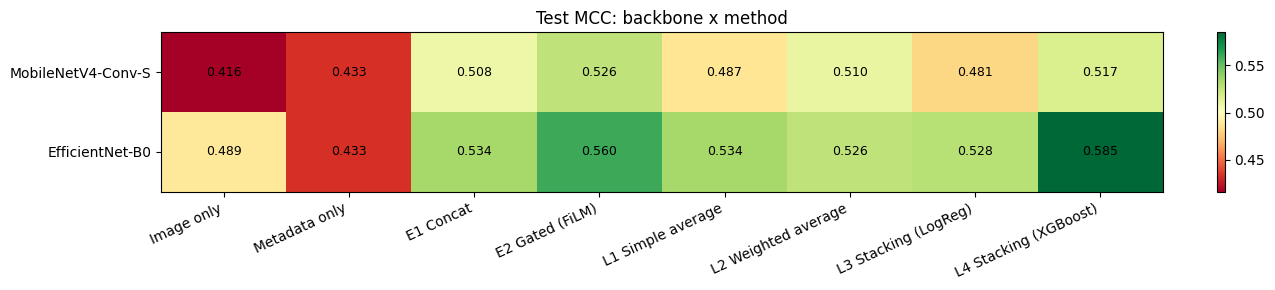

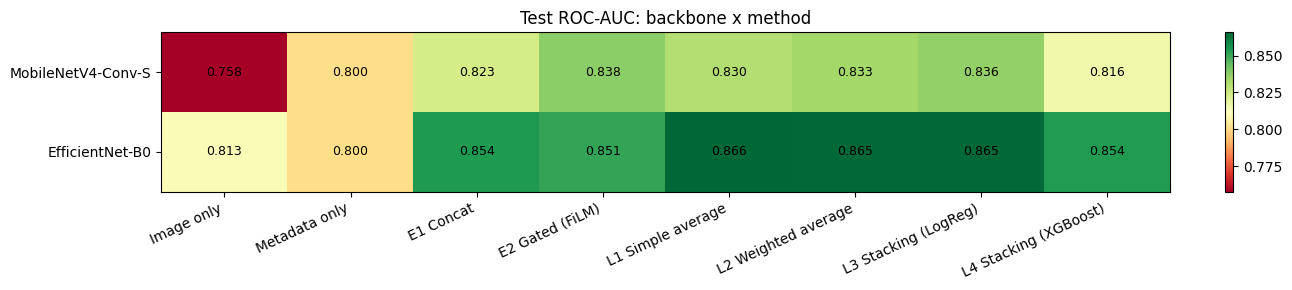

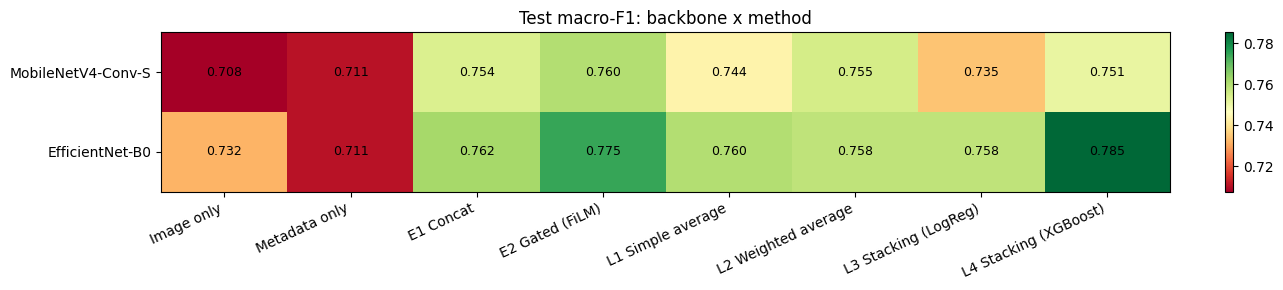

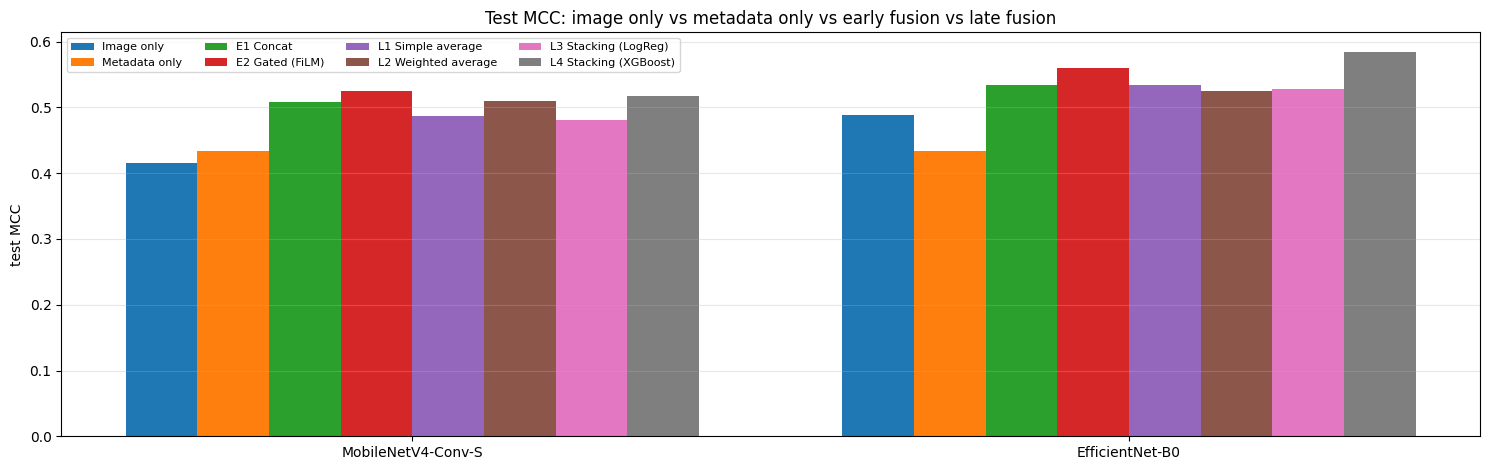

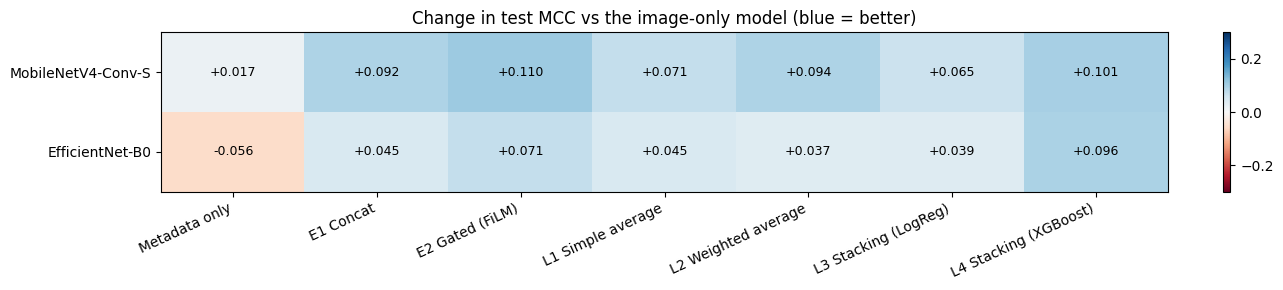

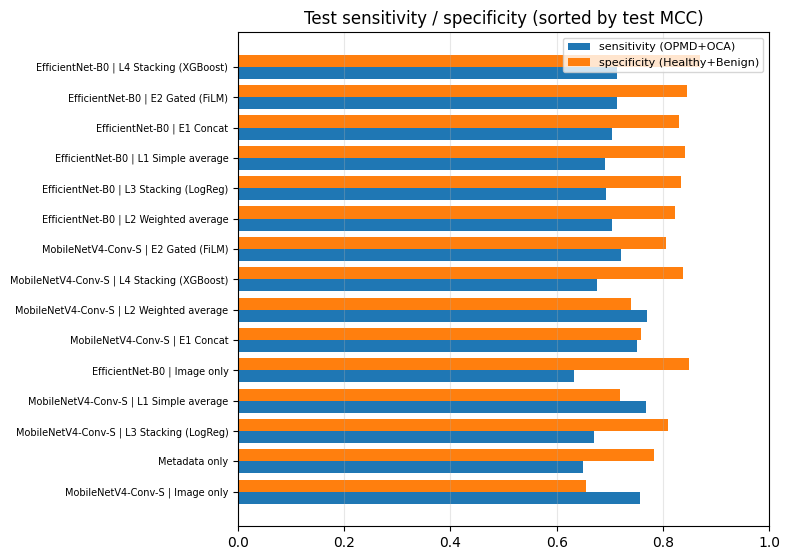

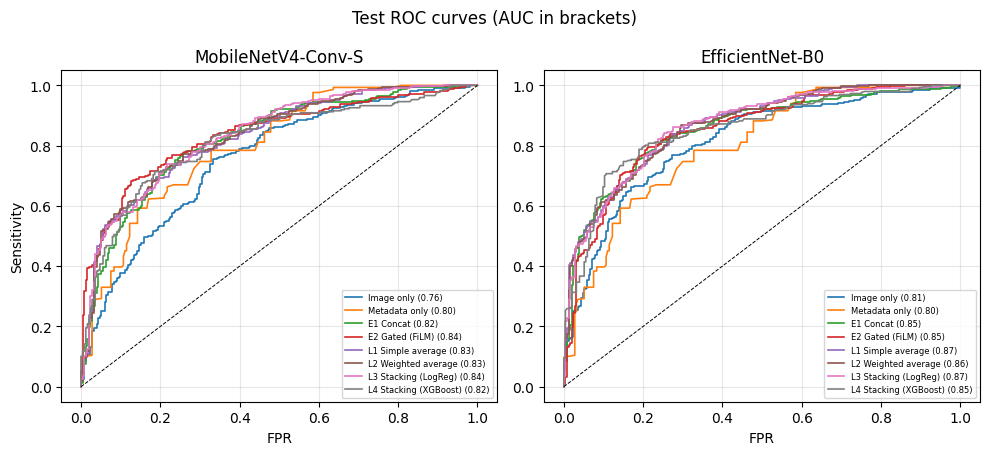

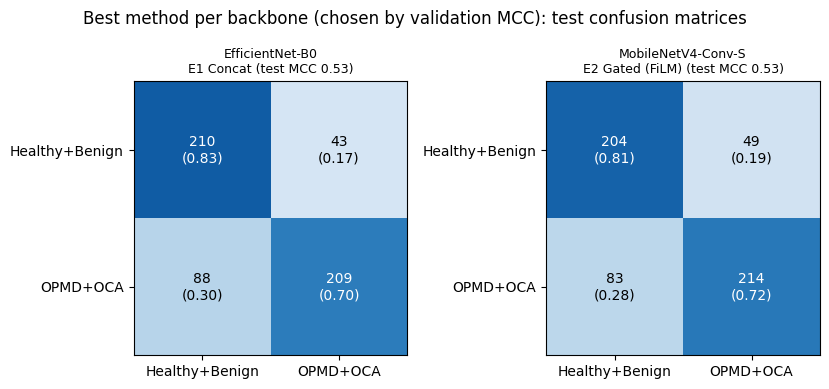

,test_Healthy_correct,test_Benign_correct,test_OPMD_correct,test_OCA_correct
model,,,,
EfficientNet-B0 | L4 Stacking (XGBoost),0.912,0.828,0.681,0.946
MobileNetV4-Conv-S | L4 Stacking (XGBoost),0.904,0.773,0.650,0.865
MobileNetV4-Conv-S | E1 Concat,0.768,0.750,0.735,0.865
MobileNetV4-Conv-S | E2 Gated (FiLM),0.808,0.805,0.700,0.865
EfficientNet-B0 | E1 Concat,0.912,0.750,0.688,0.811
EfficientNet-B0 | E2 Gated (FiLM),0.880,0.812,0.700,0.811
MobileNetV4-Conv-S | Image only,0.672,0.641,0.754,0.784
MobileNetV4-Conv-S | L1 Simple average,0.760,0.680,0.781,0.676
MobileNetV4-Conv-S | L2 Weighted average,0.800,0.680,0.785,0.676


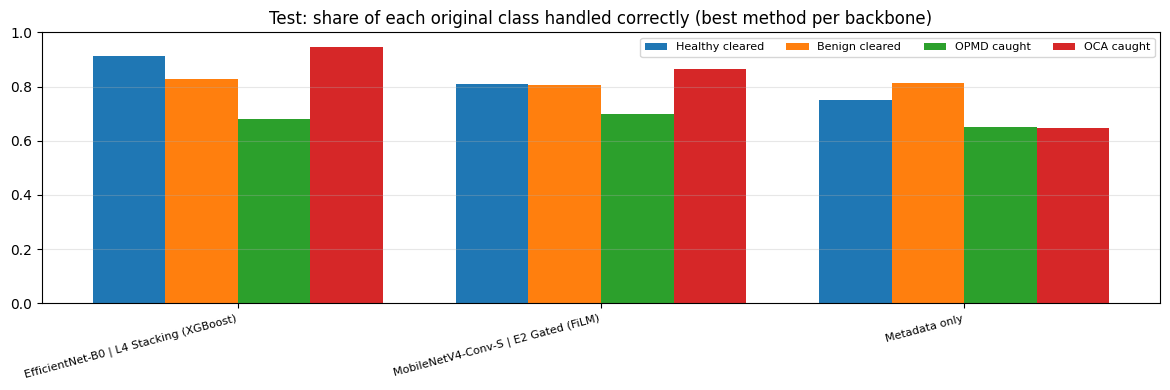

Best overall by VALIDATION MCC: EfficientNet-B0 | E1 Concat -> test MCC 0.534, acc 0.762, AUC 0.854


In [9]:
R = pd.DataFrame(RESULTS)
ORDER = ["Image only", "Metadata only", "E1 Concat", "E2 Gated (FiLM)", "L1 Simple average", "L2 Weighted average",
         "L3 Stacking (LogReg)", "L4 Stacking (XGBoost)"]
bbs = [b["name"] for b in BACKBONES if b["name"] in set(R.backbone)]
meta_row = R[R.method == "Metadata only"].iloc[0]
CD = PLOT_DIR / "comparison"
pd.set_option("display.width", 250)
show = ["backbone", "method", "group", "val_mcc", "test_accuracy", "test_macro_precision", "test_macro_recall",
        "test_macro_f1", "test_mcc", "test_roc_auc", "test_sensitivity_OPMD_OCA", "test_specificity_Benign"]
display(R[show].sort_values(["backbone", "test_mcc"], ascending=[True, False]).round(3))
R.round(4).to_csv(OUT_DIR / "comparison_table.csv", index=False)


def grid(metric):
    G = pd.DataFrame(index=bbs, columns=ORDER, dtype=float)
    for _, r in R.iterrows():
        if r.method == "Metadata only":
            G.loc[:, "Metadata only"] = r[metric]
        elif r.backbone in bbs:
            G.loc[r.backbone, r.method] = r[metric]
    return G


# 1. heatmaps of test MCC and AUC
for k, (metric, title) in enumerate((("test_mcc", "Test MCC"), ("test_roc_auc", "Test ROC-AUC"), ("test_macro_f1", "Test macro-F1"))):
    G = grid(metric)
    fig, ax = plt.subplots(figsize=(13, 0.6 * len(bbs) + 1.8))
    im = ax.imshow(G.values.astype(float), cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER, rotation=25, ha="right"); ax.set_yticks(range(len(bbs))); ax.set_yticklabels(bbs)
    for i in range(len(bbs)):
        for j in range(len(ORDER)):
            v = G.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=.03); ax.set_title(f"{title}: backbone x method")
    plt.tight_layout(); fig.savefig(CD / f"0{2 + k}_{metric}_heatmap.png", dpi=130); plt.show()

# 2. grouped bars: test MCC per backbone and method
G = grid("test_mcc"); x = np.arange(len(bbs)); w = 0.8 / len(ORDER)
fig, ax = plt.subplots(figsize=(15, 4.8))
for k, m in enumerate(ORDER):
    ax.bar(x + (k - len(ORDER) / 2 + .5) * w, G[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(bbs); ax.set_ylabel("test MCC"); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8, ncol=4)
ax.set_title("Test MCC: image only vs metadata only vs early fusion vs late fusion"); plt.tight_layout()
fig.savefig(CD / "05_test_mcc_bars.png", dpi=130); plt.show()

# 3. gain over image-only
Gain = G.drop(columns=["Image only"]).sub(G["Image only"], axis=0)
fig, ax = plt.subplots(figsize=(13, 0.6 * len(bbs) + 1.8))
im = ax.imshow(Gain.values.astype(float), cmap="RdBu", vmin=-.3, vmax=.3, aspect="auto")
ax.set_xticks(range(Gain.shape[1])); ax.set_xticklabels(Gain.columns, rotation=25, ha="right"); ax.set_yticks(range(len(bbs))); ax.set_yticklabels(bbs)
for i in range(len(bbs)):
    for j in range(Gain.shape[1]):
        ax.text(j, i, f"{Gain.values[i, j]:+.3f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, fraction=.03); ax.set_title("Change in test MCC vs the image-only model (blue = better)")
plt.tight_layout(); fig.savefig(CD / "06_gain_over_image_only.png", dpi=130); plt.show()

# 4. sensitivity / specificity of every combination
Rs = R[R.method != "Metadata only"].copy(); Rs["label"] = Rs.backbone + " | " + Rs.method
Rs = pd.concat([Rs, R[R.method == "Metadata only"].assign(label="Metadata only")]).sort_values("test_mcc")
fig, ax = plt.subplots(figsize=(8, 0.28 * len(Rs) + 1.5))
yy = np.arange(len(Rs))
ax.barh(yy - .2, Rs.test_sensitivity_OPMD_OCA, .4, label="sensitivity (OPMD+OCA)"); ax.barh(yy + .2, Rs.test_specificity_Benign, .4, label="specificity (Healthy+Benign)")
ax.set_yticks(yy); ax.set_yticklabels(Rs.label, fontsize=7); ax.set_xlim(0, 1); ax.legend(fontsize=8); ax.grid(axis="x", alpha=.3)
ax.set_title("Test sensitivity / specificity (sorted by test MCC)"); plt.tight_layout(); fig.savefig(CD / "07_sens_spec.png", dpi=130); plt.show()

# 5. ROC per backbone
fig, axes = plt.subplots(1, len(bbs), figsize=(5 * len(bbs), 4.6), squeeze=False)
for a, bb in zip(axes[0], bbs):
    for m in ORDER:
        key = ("-", m) if m == "Metadata only" else (bb, m)
        if key in PROBS:
            p = PROBS[key]["test"]; fpr, tpr, _ = roc_curve(Y["test"], p)
            a.plot(fpr, tpr, lw=1.2, label=f"{m} ({roc_auc_score(Y['test'], p):.2f})")
    a.plot([0, 1], [0, 1], "k--", lw=.7); a.set_title(bb); a.legend(fontsize=6); a.grid(alpha=.3); a.set_xlabel("FPR")
axes[0][0].set_ylabel("Sensitivity"); fig.suptitle("Test ROC curves (AUC in brackets)"); plt.tight_layout()
fig.savefig(CD / "08_roc_per_backbone.png", dpi=130); plt.show()

# 6. confusion matrices of the best method per backbone (by validation MCC)
best = R[R.backbone.isin(bbs)].sort_values("val_mcc", ascending=False).groupby("backbone").head(1)
fig, axes = plt.subplots(1, len(best), figsize=(4.2 * len(best), 3.9), squeeze=False)
for a, (_, r) in zip(axes[0], best.iterrows()):
    cm = CMS[(r.backbone, r.method, "test")]; Mn = cm / cm.sum(1, keepdims=True)
    a.imshow(Mn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}\n({Mn[i, j]:.2f})", ha="center", va="center", color="white" if Mn[i, j] > .5 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(CLASSES); a.set_yticks([0, 1]); a.set_yticklabels(CLASSES)
    a.set_title(f"{r.backbone}\n{r.method} (test MCC {r.test_mcc:.2f})", fontsize=9)
fig.suptitle("Best method per backbone (chosen by validation MCC): test confusion matrices"); plt.tight_layout()
fig.savefig(CD / "09_best_confusion.png", dpi=130); plt.show()

# 7. per original class: who is cleared / caught (test)
brk = ["test_Healthy_correct", "test_Benign_correct", "test_OPMD_correct", "test_OCA_correct"]
B = R[["backbone", "method"] + brk].copy(); B["model"] = np.where(B.backbone == "-", "Metadata only", B.backbone + " | " + B.method)
display(B.set_index("model")[brk].round(3).sort_values("test_OCA_correct", ascending=False))
best_per_bb = R.sort_values("test_mcc", ascending=False).groupby("backbone").head(1)
Bb = B.loc[best_per_bb.index]
fig, ax = plt.subplots(figsize=(12, 4)); xx = np.arange(len(Bb)); w4 = .2
for k, (col, lab) in enumerate(zip(brk, ["Healthy cleared", "Benign cleared", "OPMD caught", "OCA caught"])):
    ax.bar(xx + (k - 1.5) * w4, Bb[col], w4, label=lab)
ax.set_xticks(xx); ax.set_xticklabels(Bb.model, rotation=15, ha="right", fontsize=8); ax.set_ylim(0, 1); ax.grid(axis="y", alpha=.3)
ax.legend(fontsize=8, ncol=4); ax.set_title("Test: share of each original class handled correctly (best method per backbone)")
plt.tight_layout(); fig.savefig(CD / "10_per_original_class.png", dpi=130); plt.show()

top = R.sort_values("val_mcc", ascending=False).iloc[0]
print(f"Best overall by VALIDATION MCC: {top.backbone} | {top.method} -> test MCC {top.test_mcc:.3f}, acc {top.test_accuracy:.3f}, AUC {top.test_roc_auc:.3f}")

## 9. Package models for download

In [10]:
(MODEL_DIR / "HOW_TO_LOAD.md").write_text("""# Loading a fusion model
Each backbone folder has `Image_only/`, `E1_Concat/`, `E2_Gated_FiLM/` (weights + config) and `late_fusion/`.
`metadata_encoding.json` describes how the metadata vector is built (min-max age, one-hot categories, same order as `features`).
To rebuild a network, copy the `FusionNet` class from the notebook, then:

    model = FusionNet(cfg["timm_id"], cfg["method"], cfg["meta_dim"])     # pretrained weights not needed
    model.load_state_dict(torch.load("best_weights.pt", map_location="cpu")); model.eval()
    prob_OPMD_OCA = model(image_tensor, metadata_vector).softmax(1)[:, 1]
""")
shutil.copy(OUT_DIR / "comparison_table.csv", MODEL_DIR / "comparison_table.csv")
shutil.make_archive(str(OUT_DIR / "models"), "zip", MODEL_DIR)
print("Download:", OUT_DIR / "models.zip", f"({(OUT_DIR / 'models.zip').stat().st_size / 1e6:.0f} MB)")

Download: /kaggle/working/metadata_fusion_optionA_384_wd/models.zip (76 MB)
